# Spatially explicit negative prognosis of *Cercospora* leaf spot — minimal Colab reproduction

**Paper:** Heim RHJ et al., *A spatially explicit negative-prognosis framework for Cercospora
leaf spot using remotely sensed leaf area index*, European Journal of Plant Pathology
174(6):1181–1204 (June 2026), DOI [10.1007/s10658-026-03194-6](https://doi.org/10.1007/s10658-026-03194-6) (hybrid OA, CC-BY).
Preprint: [agriRxiv 10.31220/agrirxiv.2025.00351](https://doi.org/10.31220/agrirxiv.2025.00351).

**Author code:** research compendium
[ReneHeim/cercospoRa_compendium](https://github.com/ReneHeim/cercospoRa_compendium) (commit `ad69761e`),
R package [cercospoRa 0.0.2](https://cran.r-project.org/package=cercospoRa) (CRAN, MIT;
source inspected at `PaulMelloy/cercospoRa` commit `8570ce7`).

**Scope (partial demonstration):** run the authors' pinned R chain from compendium script
`analysis/01_lai_to_epidemic_onset.R` — per-cell LAI growth parameters → canopy closure →
spatially explicit earliest estimated epidemic onset (EEEO) map, in days after sowing (DAS) —
on the package's own minimal example (two UAV-derived LAI rasters for 2022-06-14/28 and the
IFZ Göttingen field-trial weather shipped inside cercospoRa 0.0.2). The paper's full data
share is a single 22.7 GB pCloud archive and the satellite/UAS LAI-map generation chain
(script 00, PROSAIL) is out of scope.

**Status:** executed end-to-end on a fresh Google Colab **CPU** runtime (2026-11-16); the
outputs in this notebook are the saved results of that run. No GPU is used anywhere in the
method (process-based model on two small rasters).

**AI-assisted orchestration notice (EN/JP):** Python here is *only a launcher*; every scientific
operation is the authors' own R code (cercospoRa 0.0.2 / compendium script 01) written verbatim
to `/content` and run with `Rscript`. The authors did not provide this Colab notebook; the
executed example and listed checks were validated, but untested behaviour is not guaranteed.
（日本語）Python は起動装置（ランチャー）にすぎず、科学計算はすべて著者自身の R コード
（cercospoRa 0.0.2／コンペンディアム script 01）を `/content` に書き出して `Rscript` で実行します。
著者自身はこの Colab 版を提供していません。実行した最小例と検証項目は確認済みですが、
未検証の挙動については保証されません。

## Runtime selection and how to run

**Select a CPU runtime** (`ランタイム → ランタイムのタイプを変更 → CPU`); GPU is not used and
gives no benefit for this process-based model. Then `ランタイム → すべてのセルを実行` (Run all).

**Expected duration/downloads (measured on the validation run, CPU):** setup + package install
is the dominant cost (R dependency debs via `apt`, then the pure-R cercospoRa tarball from
CRAN); the model itself runs in well under a minute. Total ≈ 5–15 min on a free Colab CPU
runtime; downloads on the order of ~100–300 MB (debs + 2.2 MB package tarball). Free-tier
times may differ.

**What you get:** canopy-closure date map, spatial EEEO map in DAS for cultivar susceptibility
6, a point-level onset estimate, per-pixel CSV exports, and the EEEO distribution.

**Known limitation:** the example uses the package's two UAV LAI rasters — it demonstrates the
method, not the paper's dataset-level accuracy or its multi-platform comparison
(10 m satellite / 1 m super-resolved / 1 m airborne).

In [ ]:
import shutil, subprocess, sys, time
from pathlib import Path
from IPython.display import Image, display

print("Python:", sys.version.split()[0])
rscript = shutil.which("Rscript")
print("Rscript:", rscript)
if rscript is None:
    raise RuntimeError(
        "R is not installed in this Colab runtime. Select a runtime with R "
        "available (standard Colab CPU image ships /usr/bin/Rscript) and rerun.")
p = subprocess.run(["Rscript", "-e", 'cat(R.version.string, "\n")'],
                   capture_output=True, text=True, timeout=120)
print(p.stdout)
p.check_returncode()

OUT = Path("/content/outputs")
OUT.mkdir(parents=True, exist_ok=True)


def run_r(name: str, src: str, timeout: int = 900) -> None:
    """Write the pinned R source to /content and run it with checked Rscript.

    Output is captured and echoed because child processes do not write to the
    Jupyter output stream directly.
    """
    path = Path("/content") / name
    path.write_text(src)
    print(f"--- Rscript {name} ---")
    p = subprocess.run(["Rscript", str(path)], capture_output=True, text=True,
                       timeout=timeout)
    if p.stdout:
        print(p.stdout[-20000:])
    if p.stderr:
        print("[stderr]", p.stderr[-4000:])
    print("[exit]", p.returncode)
    p.check_returncode()

Python: 3.13.18
Rscript: /usr/bin/Rscript


R version 4.6.1 (2026-06-24) 



### 1. System R libraries for the spatial stack

`cercospoRa` imports `terra`, `sf`, `data.table`, `lubridate`, `minpack.lm` and `circular`.
Compiled packages are installed as Ubuntu **binary debs** from the r2u/CRANapt repository
(matches the runtime's library sonames exactly; the repo is added only if missing), which
avoids 20–40 min of source compilation on the 2-core CPU runtime. The cercospoRa package
itself is pure R and installs from CRAN in seconds in the next cell.
（日本語）`terra` などコンパイル必要な依存は r2u（CRANapt）のバイナリ deb で導入し、
長いソースコンパイルを回避します。

In [ ]:
import os, subprocess, time
from pathlib import Path

env = dict(os.environ, DEBIAN_FRONTEND="noninteractive")


def sh(cmd: str, timeout: int = 2400) -> subprocess.CompletedProcess:
    p = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                       timeout=timeout, env=env)
    print("$", cmd)
    if p.stdout:
        print(p.stdout[-2500:])
    if p.returncode:
        print("[exit]", p.returncode, "|", p.stderr[-1500:])
    p.check_returncode()
    return p


t0 = time.time()
# Ensure the r2u/CRANapt binary repository for this Ubuntu release is configured
codename = subprocess.run(["lsb_release", "-cs"], capture_output=True,
                          text=True, timeout=60).stdout.strip()
if subprocess.run("apt-cache policy r-cran-terra | grep -q r2u", shell=True).returncode != 0:
    subprocess.run(
        "wget -qO- https://eddelbuettel.github.io/r2u/assets/totti_key.asc"
        " > /etc/apt/trusted.gpg.d/cranapt_key.asc",
        shell=True, check=True, timeout=300, env=env)
    Path("/etc/apt/sources.list.d/cranapt.list").write_text(
        f"deb [arch=amd64] https://r2u.stat.illinois.edu/ubuntu {codename} main\n")
    print("added r2u repository for", codename)
else:
    print("r2u repository already configured")

sh("apt-get update -qq", timeout=600)
# terra/sf and the other imports of cercospoRa as distro-matched binary debs
sh("apt-get install -y -qq r-cran-terra r-cran-sf r-cran-data.table "
   "r-cran-lubridate r-cran-minpack.lm r-cran-circular", timeout=2400)
print(f"R dependency debs ready ({time.time() - t0:.0f}s)")

r2u repository already configured


$ apt-get update -qq


$ apt-get install -y -qq r-cran-terra r-cran-sf r-cran-data.table r-cran-lubridate r-cran-minpack.lm r-cran-circular

(Reading database ... 95%
(Reading database ... 100%
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../00-r-cran-mvtnorm_1.4-2-1.ca2404.1_amd64.deb ...
Unpacking r-cran-mvtnorm (1.4-2-1.ca2404.1) ...
Selecting previously unselected package r-cran-circular.
Preparing to unpack .../01-r-cran-circular_0.5-2-1.ca2404.1_amd64.deb ...
Unpacking r-cran-circular (0.5-2-1.ca2404.1) ...
Selecting previously unselected package r-cran-proxy.
Preparing to unpack .../02-r-cran-proxy_0.4-29-1.ca2404.1_amd64.deb ...
Unpacking r-cran-proxy (0.4-29-1.ca2404.1) ...
Selecting previously unselected package r-cran-e1071.
Preparing to unpack .../03-r-cran-e1071_1.7-17-1.ca2404.1_amd64.deb ...
Unpacking r-cran-e1071 (1.7-17-1.ca2404.1) ...
Selecting previously unselected package r-cran-classint.
Preparing to unpack .../04-r-cran-classint_0.4-11-1.

### 2. Install the authors' R package

`cercospoRa` 0.0.2 is a pure-R CRAN package (no compilation), so `install.packages` fetches
and installs its 2.2 MB source tarball in seconds — **inside this Colab VM only**. The tarball
contains both the code and the example data (two UAV LAI GeoTIFFs + the field-trial weather
CSV) used below.（日本語）`cercospoRa` 0.0.2 は純 R パッケージなので CRAN から数秒で
インストールできます。例題データ（LAI GeoTIFF 2 枚と気象 CSV）もこの tarball に含まれて
おり、Colab VM 内でのみ取得します。

In [ ]:
import subprocess, time

src = r"""
options(repos = c(CRAN = "https://cloud.r-project.org"))
install.packages("cercospoRa")
cat("cercospoRa", as.character(packageVersion("cercospoRa")), "\n")
"""
t0 = time.time()
p = subprocess.run(["Rscript", "-e", src], capture_output=True, text=True,
                   timeout=2400)
print(p.stdout[-3000:])
if p.stderr:
    print("[stderr]", p.stderr[-3000:])
print(f"[exit] {p.returncode} ({time.time() - t0:.0f}s)")
p.check_returncode()

cercospoRa 0.0.2 

[stderr] Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cloud.r-project.org/src/contrib/cercospoRa_0.0.2.tar.gz'
Content type 'application/x-gzip' length 2273743 bytes (2.2 MB)
downloaded 2.2 MB

* installing *source* package ‘cercospoRa’ ...
** this is package ‘cercospoRa’ version ‘0.0.2’
** package ‘cercospoRa’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** data
*** moving datasets to lazyload DB
** inst
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
*** copying figures
** building package indices
** installing vignettes
** testing if installed package can be loaded from temporary location
** testing if installed package can be loaded from final location
** testing if installed package keeps a record of temporary installation path
* DONE (cercospoRa)

The downloaded source packages are in
	‘/tmp/RtmpbhXycF/downloaded_packages’

[exit] 0 

### 3. Verify the example inputs actually present in the package

Before any science, validate the downloaded bytes: the weather CSV must contain the
pre-formatted columns that `format_weather(time_zone = "UTC")` expects, and the two example
LAI GeoTIFFs must be readable rasters with plausible LAI ranges.（日本語）気象 CSV の列名と
2 枚の LAI GeoTIFF が期待どおりかを、計算前に検証します。

In [ ]:
run_r("verify_data.R", r"""suppressPackageStartupMessages({library(cercospoRa); library(terra)})

wpath <- system.file("extdata", "clean_weather.csv", package = "cercospoRa")
stopifnot(nzchar(wpath))
cat("weather csv:", wpath, "|", file.size(wpath), "bytes\n")
w <- read.csv(wpath)
cat("rows:", nrow(w), "| columns:", paste(names(w), collapse = ", "), "\n")
required <- c("times", "temp", "rain", "rh", "ws", "wd", "wd_sd", "lon", "lat", "station")
stopifnot(all(required %in% names(w)))

img_dir <- system.file("extdata", "uav_img", package = "cercospoRa")
imgs <- sort(list.files(img_dir, pattern = "tif$", full.names = TRUE))
stopifnot(length(imgs) >= 2)
cat("LAI rasters:", length(imgs), "file(s)\n")
for (f in imgs) {
  r <- rast(f)
  gmin <- global(r, "min", na.rm = TRUE)[[1]]
  gmax <- global(r, "max", na.rm = TRUE)[[1]]
  cat(sprintf("%s | %d layer | res %s | %d bytes | LAI min/max %.2f/%.2f\n",
              basename(f), nlyr(r), paste(format(res(r)), collapse = " x "),
              file.size(f), gmin, gmax))
}""", timeout=600)

--- Rscript verify_data.R ---


weather csv: /usr/local/lib/R/site-library/cercospoRa/extdata/clean_weather.csv | 941171 bytes
rows: 6552 | columns: X, times, temp, rh, rain, ws, wd, wd_sd, lon, lat, station, YYYY, MM, DD, hh, mm, Datum, Stunde, Minute, T.005, T020, GS200, Akku, Blatt, T005, ss 
LAI rasters: 2 file(s)
2022_06_14.tif | 1 layer | res 3.939810e-06 x 2.459073e-06 | 649169 bytes | LAI min/max 0.10/6.00
2022_06_28.tif | 1 layer | res 4.019460e-06 x 2.508795e-06 | 633191 bytes | LAI min/max 0.10/6.00

[exit] 0


### 4. Input preview — the LAI maps the model consumes

The two package-bundled UAV LAI rasters are the minimal paired input required by the method
(`read_sb_growth_parameter` needs ≥2 dates to fit the sigmoid growth). These are real
author-released example data for the same 2022 season as the paper's field trial.
（日本語）`read_sb_growth_parameter` は 2 日分の LAI ラスタを必要とします。パッケージ同梱の
2022 年の実測例題データを表示します。

--- Rscript fig_inputs.R ---


null device 
          1 
saved /content/outputs/fig_inputs.png

[exit] 0


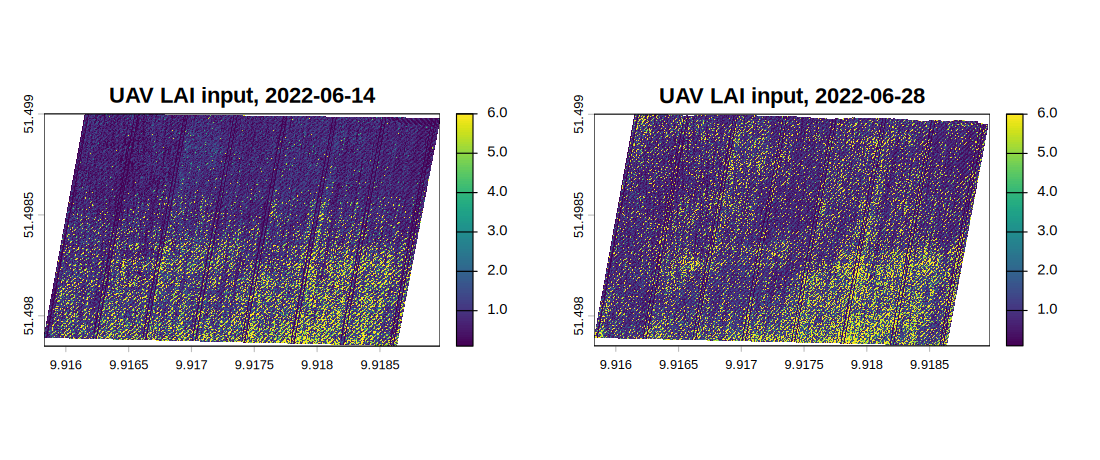

In [ ]:
run_r("fig_inputs.R", r"""suppressPackageStartupMessages(library(terra))
img_dir <- system.file("extdata", "uav_img", package = "cercospoRa")
imgs <- sort(list.files(img_dir, pattern = "tif$", full.names = TRUE))

png("/content/outputs/fig_inputs.png", width = 1100, height = 460, res = 110)
par(mfrow = c(1, 2), mar = c(4, 4, 3, 1))
plot(rast(imgs[1]), main = "UAV LAI input, 2022-06-14")
plot(rast(imgs[2]), main = "UAV LAI input, 2022-06-28")
dev.off()
cat("saved /content/outputs/fig_inputs.png\n")""", timeout=600)
display(Image(filename=str(OUT / "fig_inputs.png")))

### 5. Input preview — field-trial weather used by the negative-prognosis model

The EEEO calculation is driven by the 2022 hourly weather from the IFZ Göttingen station that
accompanied the paper's field trial (shipped as `clean_weather.csv`; the raw counterpart is
package data `weathr`).（日本語）EEEO 計算に使う 2022 年の IFZ Göttingen 観測気象データ
（`clean_weather.csv`、生データはパッケージ data `weathr`）を可視化します。

--- Rscript fig_weather.R ---


null device 
          1 
saved /content/outputs/fig_weather.png

[exit] 0


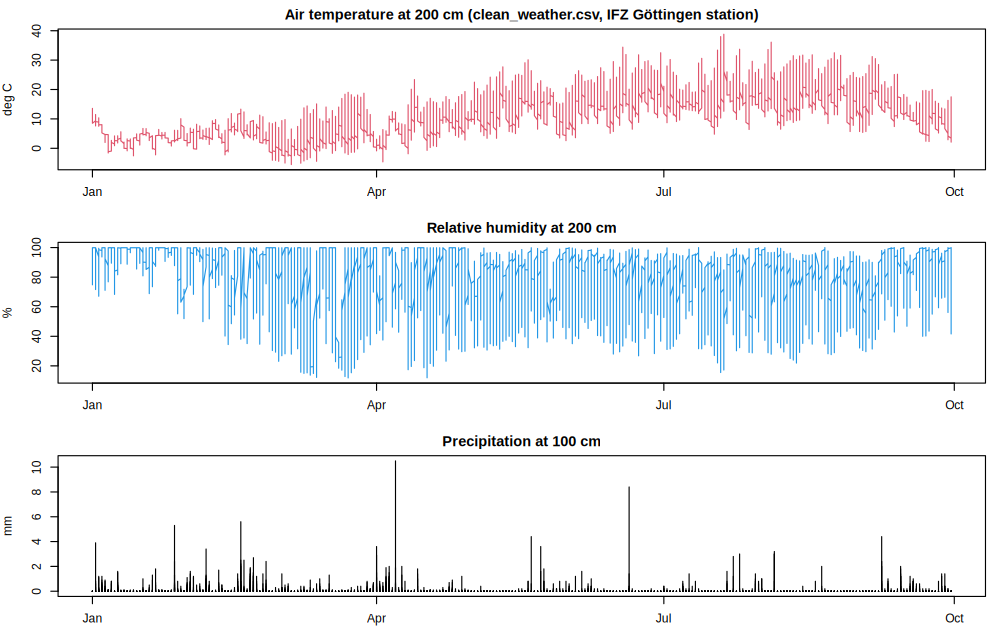

In [ ]:
run_r("fig_weather.R", r"""wpath <- system.file("extdata", "clean_weather.csv", package = "cercospoRa")
w <- read.csv(wpath)
w$times <- as.POSIXct(w$times, tz = "UTC")
w <- w[order(w$times), ]

png("/content/outputs/fig_weather.png", width = 1000, height = 640, res = 110)
par(mfrow = c(3, 1), mar = c(3, 4, 2, 1))
plot(w$times, w$temp, type = "l", col = 2, xlab = "", ylab = "deg C",
     main = "Air temperature at 200 cm (clean_weather.csv, IFZ Göttingen station)")
plot(w$times, w$rh, type = "l", col = 4, xlab = "", ylab = "%",
     main = "Relative humidity at 200 cm")
plot(w$times, w$rain, type = "h", xlab = "", ylab = "mm",
     main = "Precipitation at 100 cm")
dev.off()
cat("saved /content/outputs/fig_weather.png\n")""", timeout=600)
display(Image(filename=str(OUT / "fig_weather.png")))

### 6. Core method — per-cell growth fit, canopy closure, and the EEEO map

This is the paper's central operation, copied parameter-for-parameter from compendium script
`01_lai_to_epidemic_onset.R` (commit `ad69761e`) and the package vignette:

| Operation | Author source | Parameters used |
| --- | --- | --- |
| weather formatting | `format_weather()` | `time_zone = "UTC"` |
| LAI growth parameters | `read_sb_growth_parameter()` | `target_res = 10` m |
| sigmoid r, x0 per pixel | `calc_r_x0()` | `min_r = 0.02, max_r = 0.05, k = 6` |
| canopy closure | `calc_c_closure()` | `x1 = 1.3, k = 6` |
| EEEO map | `calc_epidemic_onset_from_image()` | 2022-04-25 → 2022-09-30, `cultivar_sus = 6` |
| DAS conversion | script 01 line 104 | sowing 2022-03-31, `(onset − sowing)/86400` |

The only adaptations: package-bundled example rasters replace the compendium's external LAI
map directories, `system.file()` paths replace `here::here()` project paths, and a single
representative `cultivar_sus = 6` replaces the 1:9 sweep.（日本語）コンペンディアム script 01
と同一のパラメータで、成長速度フィット → 被度閉鎖日 → 空間的 EEEO マップ（播種後日数）を
計算します。例題ラスタ・パスの扱いのみ適応しています。

In [ ]:
run_r("core_model.R", r"""suppressPackageStartupMessages({library(cercospoRa); library(terra)})

## ---- Weather (compendium analysis/01_lai_to_epidemic_onset.R, lines 42-44) ----
## clean_weather.csv is the pre-formatted version of the IFZ Göttingen field-trial
## weather (package data `weathr`); compendium 01 calls format_weather(time_zone="UTC").
wethr <- read.csv(system.file("extdata", "clean_weather.csv", package = "cercospoRa"))
wethr <- format_weather(wethr, time_zone = "UTC")

## ---- LAI growth parameters (compendium 01, lines 63-75) ----
img_dir <- system.file("extdata", "uav_img", package = "cercospoRa")
img_files <- sort(list.files(img_dir, pattern = "tif$", full.names = TRUE))
img_dates <- as.POSIXct(
  as.Date(sub("\\.tif$", "", basename(img_files)), format = "%Y_%m_%d"), tz = "UTC")
epidemic_onset_param <- read_sb_growth_parameter(
  img_files = img_files, img_dates = img_dates, target_res = 10)

## ---- Sigmoid growth rate r and x0, then canopy closure (compendium 01, 78-90) ----
param_rxt <- calc_r_x0(epidemic_onset_param, min_r = 0.02, max_r = 0.05, k = 6)
c_closure <- calc_c_closure(param_rxt, x1 = 1.3, k = 6)

## ---- Earliest estimated epidemic onset (EEEO) map (compendium 01, 93-104) ----
start <- as.POSIXct("2022-04-25", tz = "UTC")
end <- as.POSIXct("2022-09-30", tz = "UTC")
sowing_num <- as.numeric(as.POSIXct("2022-03-31", tz = "UTC"))
cultivar_sus <- 6  # representative value; the compendium sweeps 1:9

epidemic_onset_map <- calc_epidemic_onset_from_image(
  start = start, end = end, cc_r = c_closure, weather = wethr,
  cultivar_sus = cultivar_sus)
epidemic_onset_das <- (epidemic_onset_map - sowing_num) / (3600 * 24)  # days after sowing

## ---- Point-level onset for one canopy-closure date (package vignette, chunk 8) ----
eo_point <- calc_epidemic_onset(start = start, end = end,
                                c_closure = as.POSIXct("2022-07-30", tz = "UTC"),
                                weather = wethr, cultivar_sus = cultivar_sus)
cat("point calc_epidemic_onset (c_closure 2022-07-30, sus =", cultivar_sus, "):",
    format(eo_point), "\n")

## ---- Summary statistics and exports ----
onset_vals <- values(epidemic_onset_map)
onset_vals <- onset_vals[!is.na(onset_vals)]
onset_dates <- as.POSIXct(onset_vals, tz = "UTC", origin = "1970-01-01")
s <- summary(onset_dates)
cat("EEEO summary over pixels with a valid onset:\n")
print(s)
write.csv(data.frame(statistic = names(s), eeeo = as.character(s)),
          "/content/outputs/eeeo_summary.csv", row.names = FALSE)

das <- as.numeric(difftime(onset_dates, as.POSIXct("2022-03-31", tz = "UTC"),
                           units = "days"))
cc_vals <- values(c_closure)
cc_vals <- cc_vals[!is.na(cc_vals)]
## calc_c_closure returns days since 1970-01-01 (t0/86400 + ...), not seconds
cc_dates <- as.Date(cc_vals, origin = "1970-01-01")
cat("canopy closure dates: range", format(min(cc_dates)), "to", format(max(cc_dates)),
    "| n =", length(cc_dates), "pixels\n")
write.csv(data.frame(pixel = seq_along(cc_dates),
                     canopy_closure = format(cc_dates, "%Y-%m-%d")),
          "/content/outputs/canopy_closure_per_pixel.csv", row.names = FALSE)

## ---- Figure: inputs vs predicted EEEO ----
png("/content/outputs/fig_eeeo.png", width = 1500, height = 480, res = 110)
par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
plot(rast(img_files[1]), main = "Input: UAV LAI 2022-06-14")
plot(rast(img_files[2]), main = "Input: UAV LAI 2022-06-28")
plot(epidemic_onset_das, main = "Predicted EEEO (days after sowing)")
dev.off()

## ---- Figure: EEEO distribution (vignette-style boxplot, DAS units) ----
png("/content/outputs/fig_boxplot.png", width = 700, height = 500, res = 110)
boxplot(das, ylab = "EEEO (days after sowing)",
        main = sprintf("EEEO distribution, %d valid pixels (sus = %d)",
                       length(das), cultivar_sus))
dev.off()
cat("saved fig_eeeo.png and fig_boxplot.png\n")""", timeout=1800)

--- Rscript core_model.R ---


point calc_epidemic_onset (c_closure 2022-07-30, sus = 6 ): 2022-08-17 
EEEO summary over pixels with a valid onset:
                 Min.               1st Qu.                Median 
"2022-05-23 00:00:00" "2022-06-19 12:00:00" "2022-07-07 00:00:00" 
                 Mean               3rd Qu.                  Max. 
"2022-07-02 16:03:58" "2022-07-17 00:00:00" "2022-08-04 00:00:00" 
canopy closure dates: range 2022-04-12 to 2022-07-20 | n = 363 pixels
null device 
          1 
null device 
          1 
saved fig_eeeo.png and fig_boxplot.png

[exit] 0


### 7. Results — inputs vs predicted EEEO, distribution, and table

`fig_eeeo.png` puts the two input LAI maps beside the predicted EEEO map (days after sowing);
the boxplot shows the pixel-wise EEEO distribution in the vignette's style; the summary table
and per-pixel CSV are the small quantitative export. These are this notebook's computed
outputs, not paper figures.（日本語）入力 2 枚の LAI と予測 EEEO マップ（播種後日数）、
EEEO の分布、要約表を表示します。これらは本ノートブックの計算出力であり、論文の図では
ありません。

fig_inputs.png


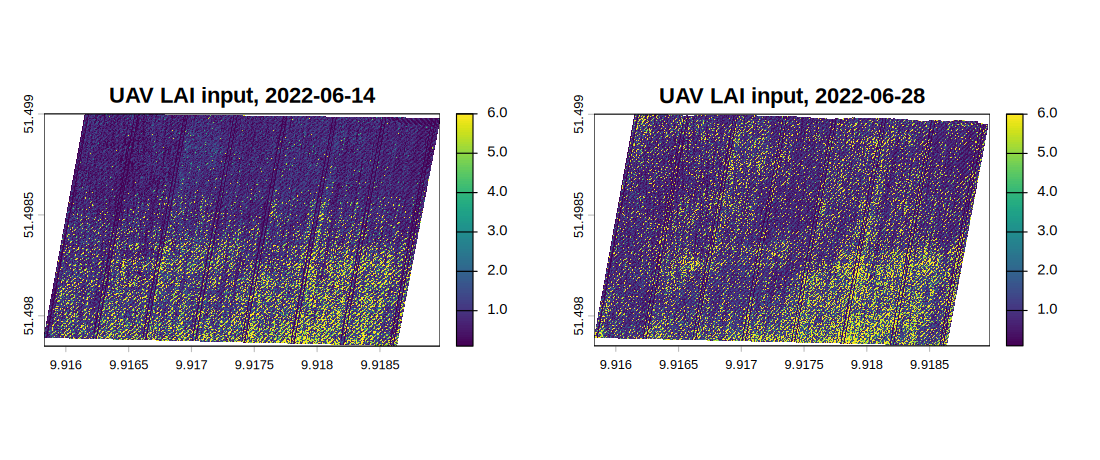

fig_weather.png


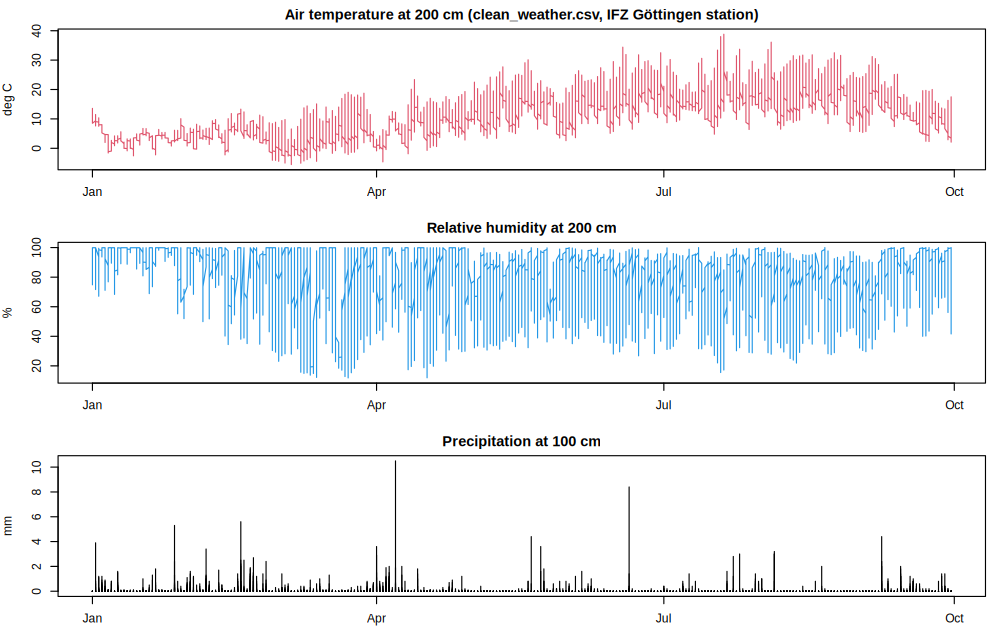

fig_eeeo.png


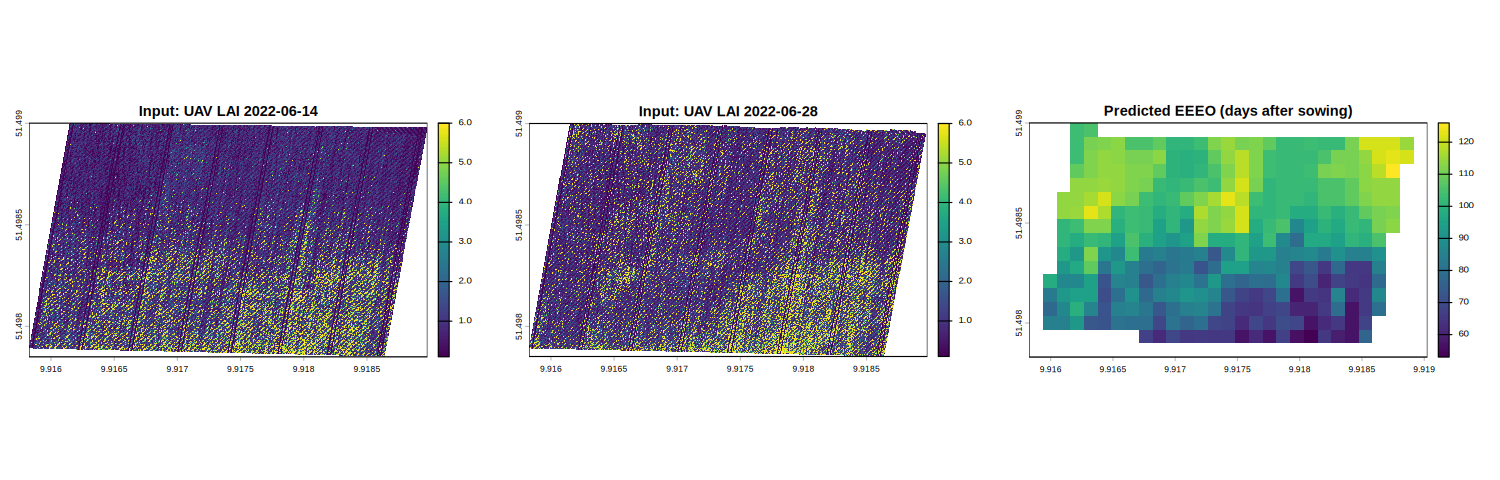

fig_boxplot.png


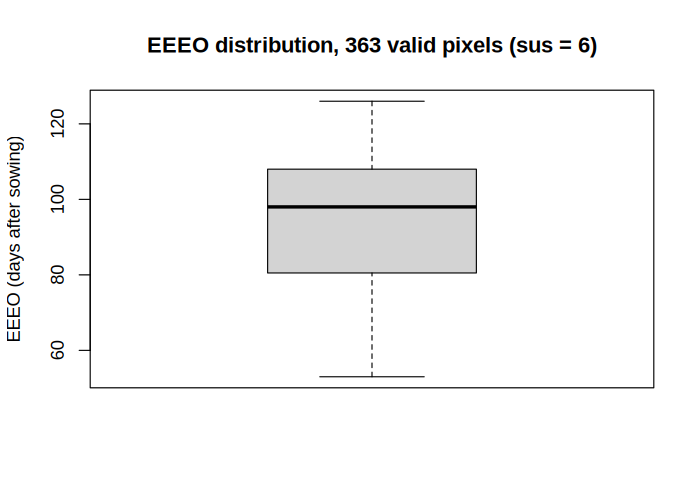

In [ ]:
for fig in ["fig_inputs.png", "fig_weather.png", "fig_eeeo.png", "fig_boxplot.png"]:
    print(fig)
    display(Image(filename=str(OUT / fig)))

### 8. Summary table and CSV export

（日本語）EEEO の要約統計と画素ごとの被度閉鎖日を表と CSV で出力します。

In [ ]:
import pandas as pd

eeeo = pd.read_csv(OUT / "eeeo_summary.csv")
cc = pd.read_csv(OUT / "canopy_closure_per_pixel.csv")
display(eeeo)
print("canopy closure per pixel:", len(cc), "rows")
display(cc["canopy_closure"].describe(include="all").to_frame("canopy_closure_date"))
print("CSV exports kept under /content/outputs/ (eeeo_summary.csv, canopy_closure_per_pixel.csv)")

,statistic,eeeo
0,Min.,2022-05-23
1,1st Qu.,2022-06-19 12:00:00
2,Median,2022-07-07
3,Mean,2022-07-02 16:03:58.01653
4,3rd Qu.,2022-07-17
5,Max.,2022-08-04


canopy closure per pixel: 363 rows


,canopy_closure_date
count,363
unique,83
top,2022-06-26
freq,16


CSV exports kept under /content/outputs/ (eeeo_summary.csv, canopy_closure_per_pixel.csv)


## Interpretation, differences, and validation record

**What was reproduced:** the paper's core spatial negative-prognosis computation — LAI-driven
per-pixel sigmoid growth → canopy closure → earliest estimated epidemic onset (EEEO) map —
executed with the authors' own `cercospoRa` implementation on the package's minimal example.
This demonstrates the method; it does **not** verify the paper's dataset-level results
(field-trial accuracy, the EEEO-vs-EO comparison, or the multi-platform LAI comparison).

**Differences from the paper's full pipeline:** the compendium's LAI maps are generated from
satellite/UAS imagery by script 00 (PROSAIL RTM) using the 22.7 GB pCloud data archive — out
of scope here. The canopy closure for the point estimate (`2022-07-30`) is the vignette's
illustrative value, not an observed field value. `cultivar_sus = 6` is one representative
value of the compendium's `1:9` sweep.

**Validation record:** executed top-to-bottom on a fresh Colab CPU runtime on 2026-11-16;
all cells completed without error and the outputs above are from that run (see the linked
execution report). Reference values for the point estimate are shown in the vignette;
pixel-level values depend on the installed package version.

**References:** Heim et al. 2026, Eur J Plant Pathol 174:1181–1204, DOI
10.1007/s10658-026-03194-6; preprint DOI 10.31220/agrirxiv.2025.00351; compendium
`ReneHeim/cercospoRa_compendium` @ `ad69761e`; `cercospoRa` 0.0.2 (CRAN, MIT), source
`PaulMelloy/cercospoRa` @ `8570ce7`; compendium data CC0 (attribution requested).